In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.typing import NDArray
plt.style.use('ggplot')

In [ ]:
def sigmoid(theta: NDArray) -> NDArray:
    return 1 / (1 + np.exp(-theta))

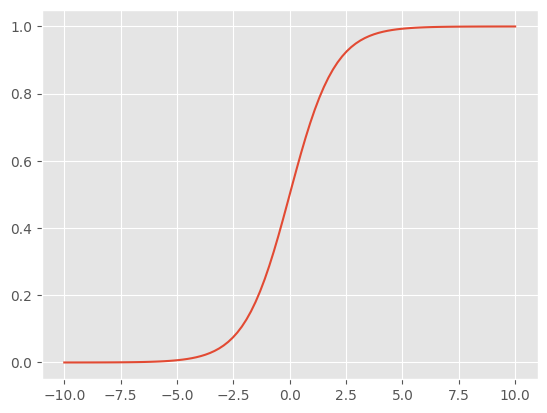

In [ ]:
x = np.linspace(-10, 10, 100)
y = sigmoid(x)
plt.plot(x, y)

In [ ]:
def neuron(x: NDArray, w: NDArray) -> NDArray:
    return sigmoid(x @ w)

\begin{equation}
\hat{y} = f(\vec{x} \cdot \vec{w} + b)\\
\tilde{x} = [x_0, x_1, \dots, x_m, 1]\\
\tilde{w} = [w_0, w_1, \dots, w_m, b]\\
\hat{y} = f(\tilde{x} \cdot \tilde{w})
\end{equation}

$\frac{d\mathcal{L}}{d\vec{w}}=-\frac{\tilde{y} - y}{y(1 - \tilde{y})}\tilde{y}(1 - \tilde{y}) \vec{x}$

In [ ]:
def derivative_w(x: NDArray, y: NDArray, w: NDArray) -> NDArray:
    tilde_y = neuron(x, w)
    return (tilde_y - y) * tilde_y * (1 - tilde_y) * x.reshape(-1, 1) / (y * (1 - tilde_y) + 1e-3)

* Ejemplos

In [ ]:
X = np.array([
    [0, 0,],
    [0, 1],
    [1, 0],
    [1, 1],
]).astype(np.float32)
X

array([[0., 0.],
       [0., 1.],
       [1., 0.],
       [1., 1.]], dtype=float32)

In [ ]:
X_tilde = np.concatenate([X, np.ones((4, 1))], axis=1)
X_tilde

array([[0., 0., 1.],
       [0., 1., 1.],
       [1., 0., 1.],
       [1., 1., 1.]])

In [ ]:
y = np.array([0, 0, 0, 1]).astype(np.float32).reshape(-1, 1)
y

array([[0.],
       [0.],
       [0.],
       [1.]], dtype=float32)

In [ ]:
w_0 = np.random.normal(size=(3, 1))
w_0

array([[1.37718888],
       [1.16393066],
       [0.51753362]])

In [ ]:
neuron(X_tilde, w_0)

array([[0.64673825],
       [0.70898356],
       [0.34442694],
       [0.41146618]])

In [ ]:
y

array([[0.],
       [0.],
       [0.],
       [1.]], dtype=float32)

In [ ]:
def binary_cross_entropy(y: NDArray, y_hat: NDArray) -> float:
    return - (y * np.log(y_hat) + (1 - y) * np.log(1 - y_hat)).mean()

In [ ]:
def optimize(X: NDArray, y: NDArray, w_0: NDArray, learning_rate: float, n_iters: int) -> NDArray:
    w = w_0.copy()
    for _ in range(n_iters):
        for i in range(X.shape[0]):
            w = w - learning_rate * derivative_w(X[i], y[i], w)
        y_hat = neuron(X, w)
        print(binary_cross_entropy(y, y_hat))
    return w

In [ ]:
w = optimize(X_tilde, y, w_0, 1e-4, 300)
w

1.2046690662429882
1.179747672280043
1.15472078630159
1.129615383605478
1.104461159815693
1.0792905936583483
1.0541389719627319
1.029044368196983
1.00404756558454
0.9791919160247863
0.9545231267892511
0.93008896840305
0.9059388993410515
0.8821236062091407
0.8586944619078608
0.8357029087584835
0.8131997784722867
0.7912345658184305
0.7698546774627368
0.7491046812292813
0.7290255835077767
0.7096541632975732
0.6910223901929928
0.6731569504217891
0.6560789000212763
0.6398034577649647
0.6243399430995543
0.6096918567800448
0.5958570947704849
0.5828282798999969
0.570593191166414
0.5591352677066416
0.5484341633438222
0.5384663281354574
0.5292055952063532
0.5206237539975646
0.5126910945145431
0.5053769108538778
0.4986499559233538
0.4924788426133803
0.4868323895764099
0.48167991214473105
0.47699146074638343
0.4727380104895714
0.46889160643351413
0.465425469520246
0.4623140682852192
0.45953316137017697
0.45705981559799436
0.45487240399437445
0.4529505877029509
0.4512752852753376
0.4498286323532282

array([[ 0.18544404],
       [ 0.08707272],
       [-2.52473673]])

In [ ]:
neuron(X_tilde, w)

array([[0.07414214],
       [0.08034535],
       [0.08792062],
       [0.09515815]])